In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow verzija:", tf.__version__)

TensorFlow verzija: 2.21.0


In [2]:
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

TRAIN_PATH = "../Dataset_Splitted/train"
VAL_PATH = "../Dataset_Splitted/val"
TEST_PATH = "../Dataset_Splitted/test"

print("Train:", TRAIN_PATH)
print("Validation:", VAL_PATH)
print("Test:", TEST_PATH)

Train: ../Dataset_Splitted/train
Validation: ../Dataset_Splitted/val
Test: ../Dataset_Splitted/test


In [3]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

evaluation_datagen = ImageDataGenerator()

In [4]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

Found 2562 images belonging to 5 classes.


In [5]:
validation_generator = evaluation_datagen.flow_from_directory(
    VAL_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 546 images belonging to 5 classes.


In [6]:
test_generator = evaluation_datagen.flow_from_directory(
    TEST_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 554 images belonging to 5 classes.


In [7]:
print("Train rescale:", train_datagen.rescale)
print("Evaluation rescale:", evaluation_datagen.rescale)

Train rescale: None
Evaluation rescale: None


In [8]:
batch_images, batch_labels = next(train_generator)

print("Oblik slika:", batch_images.shape)
print("Minimum:", batch_images.min())
print("Maksimum:", batch_images.max())

train_generator.reset()

Oblik slika: (32, 224, 224, 3)
Minimum: 0.0
Maksimum: 255.0


In [9]:
print("Indeksi klasa:", train_generator.class_indices)
print("Broj klasa:", train_generator.num_classes)

Indeksi klasa: {'Mild_DR': 0, 'Moderate_DR': 1, 'No_DR': 2, 'Proliferate_DR': 3, 'Severe_DR': 4}
Broj klasa: 5


In [10]:
model = load_model(
    "../Models/efficientnet_model.keras"
)

print("Model učitan.")
print("Izlaz modela:", model.output_shape)

Model učitan.
Izlaz modela: (None, 5)


In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.TopKCategoricalAccuracy(
            k=2,
            name="top2_accuracy"
        )
    ]
)

print("Model je kompajliran.")

Model je kompajliran.


In [12]:
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)

class_weights = {
    class_index: float(weight)
    for class_index, weight in enumerate(class_weight_values)
}

print("Težine klasa:")
print(class_weights)

Težine klasa:
{0: 1.9783783783783784, 1: 0.7330472103004292, 2: 0.40570071258907364, 3: 2.487378640776699, 4: 3.7955555555555556}


In [13]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    "../Saved_Models/best_model_corrected.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

In [14]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=15,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_learning_rate,
        model_checkpoint
    ]
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 682ms/step - accuracy: 0.3782 - loss: 1.8181 - top2_accuracy: 0.5890
Epoch 1: val_loss improved from None to 1.17703, saving model to ../Saved_Models/best_model_corrected.keras

Epoch 1: finished saving model to ../Saved_Models/best_model_corrected.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 76s 831ms/step - accuracy: 0.3782 - loss: 1.8181 - top2_accuracy: 0.5890 - val_accuracy: 0.5934 - val_loss: 1.1770 - val_top2_accuracy: 0.7436 - learning_rate: 1.0000e-04
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 721ms/step - accuracy: 0.5679 - loss: 1.3910 - top2_accuracy: 0.7537
Epoch 2: val_loss improved from 1.17703 to 1.02280, saving model to ../Saved_Models/best_model_corrected.keras

Epoch 2: finished saving model to ../Saved_Models/best_model_corrected.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 68s 836ms/step - accuracy: 0.5679 - loss: 1.3910 - top2_accuracy: 0.7537 - val_accuracy: 0.6429 - val_loss: 1.0228 - val_top2_accuracy: 0.8059 - learning_rate: 1.0000e-04
Epoch 3/1

In [15]:
from tensorflow.keras.models import load_model

best_model = load_model(
    "../Saved_Models/best_model_corrected.keras"
)

print("Najbolji model je učitan.")

Najbolji model je učitan.


In [16]:
test_generator.reset()

test_loss, test_accuracy, test_top2_accuracy = best_model.evaluate(
    test_generator
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test top-2 accuracy:", test_top2_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 13s 479ms/step - accuracy: 0.7347 - loss: 0.6338 - top2_accuracy: 0.9007
Test loss: 0.63382488489151
Test accuracy: 0.7346570491790771
Test top-2 accuracy: 0.9007220268249512


In [17]:
from sklearn.metrics import classification_report
import numpy as np

test_generator.reset()

predictions = best_model.predict(
    test_generator
)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

class_names = list(
    test_generator.class_indices.keys()
)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

18/18 ━━━━━━━━━━━━━━━━━━━━ 13s 599ms/step
                precision    recall  f1-score   support

       Mild_DR       0.40      0.75      0.53        56
   Moderate_DR       0.71      0.47      0.57       151
         No_DR       0.97      0.97      0.97       272
Proliferate_DR       0.56      0.33      0.42        45
     Severe_DR       0.30      0.53      0.39        30

      accuracy                           0.73       554
     macro avg       0.59      0.61      0.57       554
  weighted avg       0.77      0.73      0.74       554



In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

[[ 42  10   2   0   2]
 [ 44  71   5   8  23]
 [  9   0 263   0   0]
 [  6  12   0  15  12]
 [  3   7   0   4  16]]


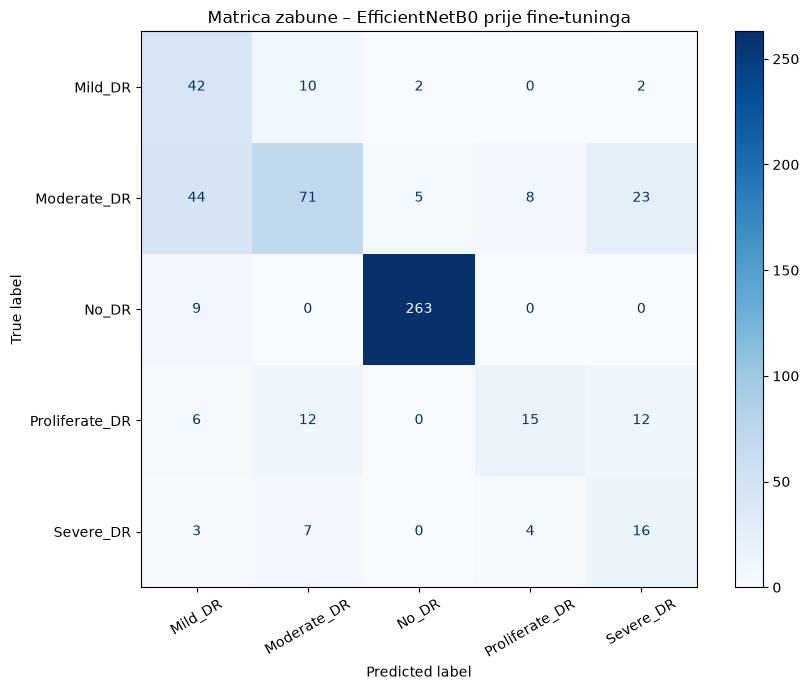

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30,
    values_format="d"
)

plt.title("Matrica zabune – EfficientNetB0 prije fine-tuninga")
plt.tight_layout()
plt.show()

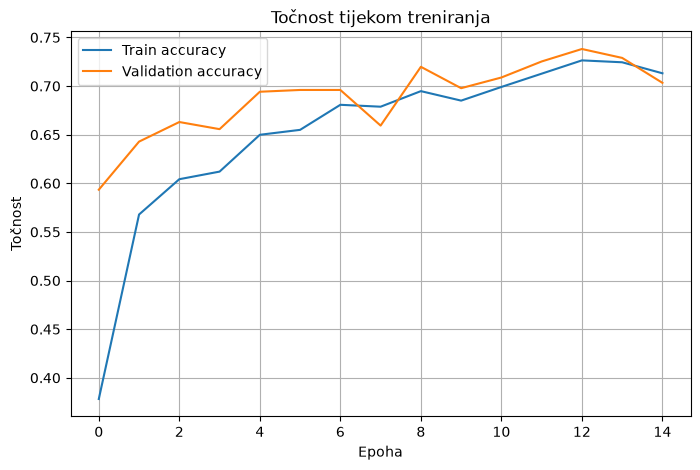

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoha")
plt.ylabel("Točnost")
plt.title("Točnost tijekom treniranja")
plt.legend()
plt.grid()
plt.show()

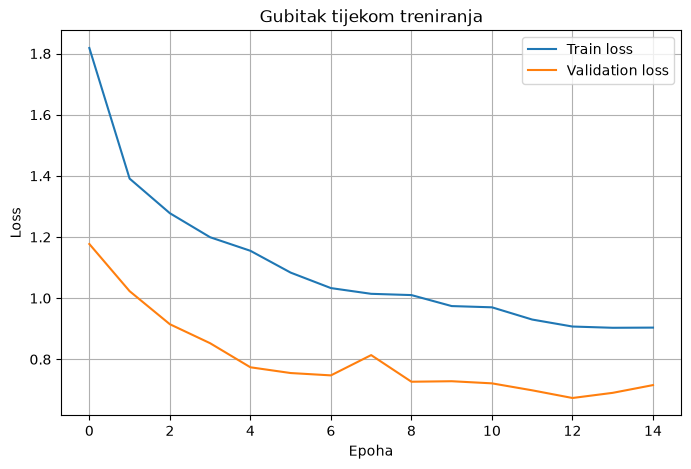

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Train loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoha")
plt.ylabel("Loss")
plt.title("Gubitak tijekom treniranja")
plt.legend()
plt.grid()
plt.show()

In [22]:
from tensorflow.keras.models import load_model

fine_tuning_model = load_model(
    "../Saved_Models/best_model_corrected.keras"
)

print("Model učitan.")

Model učitan.


In [23]:
for index, layer in enumerate(fine_tuning_model.layers):
    print(index, layer.name, type(layer).__name__, layer.trainable)

0 input_layer InputLayer True
1 rescaling Rescaling False
2 normalization Normalization False
3 rescaling_1 Rescaling False
4 stem_conv_pad ZeroPadding2D False
5 stem_conv Conv2D False
6 stem_bn BatchNormalization False
7 stem_activation Activation False
8 block1a_dwconv DepthwiseConv2D False
9 block1a_bn BatchNormalization False
10 block1a_activation Activation False
11 block1a_se_squeeze GlobalAveragePooling2D False
12 block1a_se_reshape Reshape False
13 block1a_se_reduce Conv2D False
14 block1a_se_expand Conv2D False
15 block1a_se_excite Multiply False
16 block1a_project_conv Conv2D False
17 block1a_project_bn BatchNormalization False
18 block2a_expand_conv Conv2D False
19 block2a_expand_bn BatchNormalization False
20 block2a_expand_activation Activation False
21 block2a_dwconv_pad ZeroPadding2D False
22 block2a_dwconv DepthwiseConv2D False
23 block2a_bn BatchNormalization False
24 block2a_activation Activation False
25 block2a_se_squeeze GlobalAveragePooling2D False
26 block2a_se_r

In [25]:
from tensorflow.keras.models import load_model

fine_tuning_model = load_model(
    "../Saved_Models/best_model_corrected.keras"
)

print("Model je učitan.")
print("Ukupan broj slojeva:", len(fine_tuning_model.layers))

Model je učitan.
Ukupan broj slojeva: 244


In [26]:
for layer in fine_tuning_model.layers:
    layer.trainable = False

In [27]:
unfreeze = False

for layer in fine_tuning_model.layers:
    if layer.name == "block7a_expand_conv":
        unfreeze = True

    if unfreeze:
        layer.trainable = True

In [28]:
for layer in fine_tuning_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [29]:
head_layer_names = [
    "global_average_pooling2d",
    "dropout",
    "dense",
    "dropout_1",
    "dense_1"
]

for layer_name in head_layer_names:
    fine_tuning_model.get_layer(layer_name).trainable = True

In [30]:
trainable_layers = [
    layer.name
    for layer in fine_tuning_model.layers
    if layer.trainable
]

print("Broj trenirajućih slojeva:", len(trainable_layers))
print("\nTrenirajući slojevi:")

for layer_name in trainable_layers:
    print(layer_name)

Broj trenirajućih slojeva: 17

Trenirajući slojevi:
block7a_expand_conv
block7a_expand_activation
block7a_dwconv
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
top_conv
top_activation
global_average_pooling2d
dropout
dense
dropout_1
dense_1


In [31]:
for layer in fine_tuning_model.layers[-40:]:
    print(
        f"{layer.name:35s} "
        f"{type(layer).__name__:25s} "
        f"trainable={layer.trainable}"
    )

block6c_project_bn                  BatchNormalization        trainable=False
block6c_drop                        Dropout                   trainable=False
block6c_add                         Add                       trainable=False
block6d_expand_conv                 Conv2D                    trainable=False
block6d_expand_bn                   BatchNormalization        trainable=False
block6d_expand_activation           Activation                trainable=False
block6d_dwconv                      DepthwiseConv2D           trainable=False
block6d_bn                          BatchNormalization        trainable=False
block6d_activation                  Activation                trainable=False
block6d_se_squeeze                  GlobalAveragePooling2D    trainable=False
block6d_se_reshape                  Reshape                   trainable=False
block6d_se_reduce                   Conv2D                    trainable=False
block6d_se_expand                   Conv2D                    tr

In [32]:
fine_tuning_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.TopKCategoricalAccuracy(
            k=2,
            name="top2_accuracy"
        )
    ]
)

print("Model je kompajliran za fine-tuning.")

Model je kompajliran za fine-tuning.


In [33]:
fine_tuning_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

fine_tuning_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

fine_tuning_checkpoint = ModelCheckpoint(
    "../Saved_Models/best_model_finetuned.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

In [34]:
train_generator.reset()
validation_generator.reset()

In [35]:
history_fine = fine_tuning_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=15,
    class_weight=class_weights,
    callbacks=[
        fine_tuning_early_stopping,
        fine_tuning_reduce_lr,
        fine_tuning_checkpoint
    ]
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 747ms/step - accuracy: 0.7404 - loss: 0.8663 - top2_accuracy: 0.8977
Epoch 1: val_loss improved from None to 0.68581, saving model to ../Saved_Models/best_model_finetuned.keras

Epoch 1: finished saving model to ../Saved_Models/best_model_finetuned.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 83s 915ms/step - accuracy: 0.7404 - loss: 0.8663 - top2_accuracy: 0.8977 - val_accuracy: 0.7344 - val_loss: 0.6858 - val_top2_accuracy: 0.8993 - learning_rate: 1.0000e-05
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 785ms/step - accuracy: 0.7389 - loss: 0.8912 - top2_accuracy: 0.8868
Epoch 2: val_loss did not improve from 0.68581
81/81 ━━━━━━━━━━━━━━━━━━━━ 73s 897ms/step - accuracy: 0.7389 - loss: 0.8912 - top2_accuracy: 0.8868 - val_accuracy: 0.7179 - val_loss: 0.6973 - val_top2_accuracy: 0.9029 - learning_rate: 1.0000e-05
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 780ms/step - accuracy: 0.7244 - loss: 0.8325 - top2_accuracy: 0.8895
Epoch 3: ReduceLROnPlateau reducing learn

In [36]:
from tensorflow.keras.models import load_model

best_fine_model = load_model(
    "../Saved_Models/best_model_finetuned.keras"
)

print("Najbolji fine-tuned model je učitan.")

Najbolji fine-tuned model je učitan.


In [37]:
test_generator.reset()

fine_test_loss, fine_test_accuracy, fine_test_top2_accuracy = (
    best_fine_model.evaluate(test_generator)
)

print("Fine-tuned test loss:", fine_test_loss)
print("Fine-tuned test accuracy:", fine_test_accuracy)
print("Fine-tuned test top-2 accuracy:", fine_test_top2_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 15s 554ms/step - accuracy: 0.7419 - loss: 0.6394 - top2_accuracy: 0.9007
Fine-tuned test loss: 0.639386773109436
Fine-tuned test accuracy: 0.7418772578239441
Fine-tuned test top-2 accuracy: 0.9007220268249512


In [38]:
import numpy as np

from sklearn.metrics import classification_report

test_generator.reset()

fine_predictions = best_fine_model.predict(
    test_generator
)

fine_y_pred = np.argmax(
    fine_predictions,
    axis=1
)

fine_y_true = test_generator.classes

class_names = list(
    test_generator.class_indices.keys()
)

print(
    classification_report(
        fine_y_true,
        fine_y_pred,
        target_names=class_names,
        zero_division=0
    )
)

18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 670ms/step
                precision    recall  f1-score   support

       Mild_DR       0.41      0.80      0.55        56
   Moderate_DR       0.74      0.49      0.59       151
         No_DR       0.97      0.96      0.96       272
Proliferate_DR       0.59      0.38      0.46        45
     Severe_DR       0.31      0.50      0.38        30

      accuracy                           0.74       554
     macro avg       0.60      0.63      0.59       554
  weighted avg       0.79      0.74      0.75       554



In [39]:
from sklearn.metrics import confusion_matrix

fine_cm = confusion_matrix(
    fine_y_true,
    fine_y_pred
)

print(fine_cm)

[[ 45   7   2   0   2]
 [ 43  74   5   8  21]
 [ 11   1 260   0   0]
 [  6  11   0  17  11]
 [  4   7   0   4  15]]


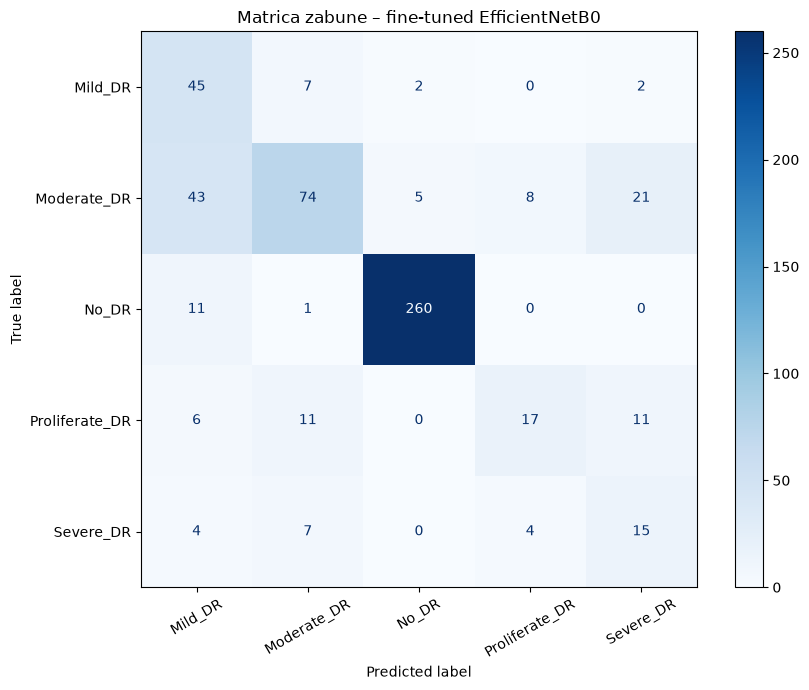

In [40]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=fine_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30,
    values_format="d"
)

plt.title("Matrica zabune – fine-tuned EfficientNetB0")
plt.tight_layout()
plt.show()